### TES NEO4J

In [9]:
%pip install python-dotenv

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 24.0 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [10]:
import os
from dotenv import load_dotenv
from neo4j import GraphDatabase

NEO4J_URI = os.getenv("NEO4J_URI")
NEO4J_USERNAME = os.getenv("NEO4J_USERNAME")
NEO4J_PASSWORD = os.getenv("NEO4J_PASSWORD")

driver = GraphDatabase.driver(
    NEO4J_URI,
    auth=(NEO4J_USERNAME, NEO4J_PASSWORD)
)
driver.verify_connectivity()

print("Koneksi Neo4j berhasil!")

Koneksi Neo4j berhasil!


C:\Users\RENDRA\AppData\Local\Temp\ipykernel_10492\2467714498.py:13: ExperimentalWarning: The configuration may change in the future.
  driver.verify_connectivity()


In [11]:
def add_friend(driver, name, friend_name):
    with driver.session(database="neo4j") as session:
        session.run(
            "MERGE (a:Person {name: $name}) "
            "MERGE (friend:Person {name: $friend_name}) "
            "MERGE (a)-[:KNOWS]->(friend)",
            name=name,
            friend_name=friend_name,
        )

In [12]:
def print_friends(driver, name):
    with driver.session(database="neo4j") as session:
        result = session.run(
            "MATCH (a:Person)-[:KNOWS]->(friend) "
            "WHERE a.name = $name "
            "RETURN friend.name AS friend_name "
            "ORDER BY friend.name",
            name=name,
        )

        for record in result:
            print(record["friend_name"])

In [13]:
with GraphDatabase.driver(NEO4J_URI, auth=(NEO4J_USERNAME, NEO4J_PASSWORD)) as driver:
    driver.verify_connectivity()

    add_friend(driver, "Arthur", "Guinevere")
    add_friend(driver, "Arthur", "Lancelot")
    add_friend(driver, "Arthur", "Merlin")

    print_friends(driver, "Arthur")

C:\Users\RENDRA\AppData\Local\Temp\ipykernel_10492\2713388473.py:2: ExperimentalWarning: The configuration may change in the future.
  driver.verify_connectivity()


Guinevere
Lancelot
Merlin


### IMPORT DATA

In [14]:
import os
import pandas as pd
from tqdm.auto import tqdm
from neo4j import GraphDatabase

NEO4J_URI = os.getenv("NEO4J_URI")
NEO4J_USERNAME = os.getenv("NEO4J_USERNAME")
NEO4J_PASSWORD = os.getenv("NEO4J_PASSWORD")

csv_file_path = os.path.join("data", "events.csv")

batch_size = 10000


def create_constraints(session):
    session.run("""
        CREATE CONSTRAINT visitor_id IF NOT EXISTS
        FOR (v:Visitor) REQUIRE v.visitorId IS UNIQUE
    """)
    session.run("""
        CREATE CONSTRAINT item_id IF NOT EXISTS
        FOR (i:Item) REQUIRE i.itemId IS UNIQUE
    """)


def import_batch(tx, batch):
    cypher_query = """
    UNWIND $batch AS row

    MERGE (v:Visitor {visitorId: row.visitorid})
    MERGE (i:Item {itemId: row.itemid})

    WITH v, i, row
    CALL {
        WITH v, i, row
        WITH v, i, row WHERE row.event = 'view'
        CREATE (v)-[:VIEWED {timestamp: row.timestamp}]->(i)

        UNION ALL

        WITH v, i, row
        WITH v, i, row WHERE row.event = 'addtocart'
        CREATE (v)-[:ADDED_TO_CART {timestamp: row.timestamp}]->(i)

        UNION ALL

        WITH v, i, row
        WITH v, i, row WHERE row.event = 'transaction'
        CREATE (v)-[:BOUGHT {
            timestamp: row.timestamp,
            transactionId: row.transactionid
        }]->(i)
    }
    """
    tx.run(cypher_query, batch=batch)

In [15]:
driver = GraphDatabase.driver(
    NEO4J_URI,
    auth=(NEO4J_USERNAME, NEO4J_PASSWORD)
)

try:
    driver.verify_connectivity()
    print("Koneksi Neo4j berhasil.")

    # Impor data secara bertahap
    with driver.session(database="neo4j") as session:
        create_constraints(session)

        print(f"Membaca file data dari: {csv_file_path}")

        chunks = pd.read_csv(
            csv_file_path,
            chunksize=batch_size
        )

        total_rows = sum(
            1 for _ in open(csv_file_path, encoding="utf-8")
        ) - 1

        total_chunks = (total_rows + batch_size - 1) // batch_size

        print("Memulai proses impor data ke Neo4j...")

        for chunk in tqdm(
            chunks,
            total=total_chunks,
            desc="Mengimpor Batch Data"
        ):
            chunk["transactionid"] = (
                chunk["transactionid"].fillna("").astype(str)
            )

            records = chunk.to_dict(orient="records")
            session.write_transaction(import_batch, records)

    print("Proses impor berhasil.")

finally:
    if hasattr(driver, "close"):
        driver.close()

C:\Users\RENDRA\AppData\Local\Temp\ipykernel_10492\1651739746.py:7: ExperimentalWarning: The configuration may change in the future.
  driver.verify_connectivity()


Koneksi Neo4j berhasil.
Membaca file data dari: data\events.csv
Memulai proses impor data ke Neo4j...


Mengimpor Batch Data: 100%|██████████| 276/276 [03:33<00:00,  1.29it/s]

Proses impor berhasil.


### **2.1**
**NOMOR 1 dan 2**

In [16]:
import pandas as pd

df = pd.read_csv(csv_file_path)

print("Jumlah baris:", len(df))
print("Kolom:", df.columns.tolist())

print("Timestamp minimum:", df["timestamp"].min())
print("Timestamp maksimum:", df["timestamp"].max())

print("\nJumlah event:")
print(df["event"].value_counts())

Jumlah baris: 2756101
Kolom: ['timestamp', 'visitorid', 'event', 'itemid', 'transactionid']
Timestamp minimum: 1430622004384
Timestamp maksimum: 1442545187788

Jumlah event:
event
view           2664312
addtocart        69332
transaction      22457
Name: count, dtype: int64


In [17]:
print(
    "Tanggal awal:",
    pd.to_datetime(df["timestamp"].min(), unit="ms")
)

print(
    "Tanggal akhir:",
    pd.to_datetime(df["timestamp"].max(), unit="ms")
)

Tanggal awal: 2015-05-03 03:00:04.384000
Tanggal akhir: 2015-09-18 02:59:47.788000


In [18]:

import pandas as pd
from pathlib import Path

df["datetime"] = pd.to_datetime(df["timestamp"], unit="ms")

p1 = df[
    (df["datetime"] >= "2015-05-03") &
    (df["datetime"] < "2015-07-01")
].copy()

p2 = df[
    (df["datetime"] >= "2015-07-01") &
    (df["datetime"] < "2015-09-01")
].copy()

Path("data/filtered").mkdir(parents=True, exist_ok=True)

p1.to_csv("data/filtered/events_P1_training.csv", index=False)
p2.to_csv("data/filtered/events_P2_testing.csv", index=False)

print("Jumlah data P1:", len(p1))
print("Jumlah data P2:", len(p2))

print("\nRentang P1:")
print(p1["datetime"].min(), "sampai", p1["datetime"].max())

print("\nRentang P2:")
print(p2["datetime"].min(), "sampai", p2["datetime"].max())

print("\nFile CSV berhasil disimpan.")


Jumlah data P1: 1201045
Jumlah data P2: 1251346

Rentang P1:
2015-05-03 03:00:04.384000 sampai 2015-06-30 23:59:59.292000

Rentang P2:
2015-07-01 00:00:06.967000 sampai 2015-08-31 23:59:58.647000

File CSV berhasil disimpan.


In [19]:
import pandas as pd

p1 = pd.read_csv("data/filtered/events_P1_training.csv")
p2 = pd.read_csv("data/filtered/events_P2_testing.csv")

print("Jumlah data P1:", len(p1))
print("Jumlah data P2:", len(p2))

Jumlah data P1: 1201045
Jumlah data P2: 1251346


**NOMOR 3**

In [20]:
from neo4j import GraphDatabase
import pandas as pd

driver = GraphDatabase.driver(
    NEO4J_URI,
    auth=(NEO4J_USERNAME, NEO4J_PASSWORD)
)

query = """
MATCH (n)
RETURN labels(n) AS JenisSimpul,
       count(n) AS Jumlah
ORDER BY JenisSimpul
"""

with driver.session() as session:
    result = session.run(query)
    data = [record.data() for record in result]

df_simpul = pd.DataFrame(data)
display(df_simpul)

,JenisSimpul,Jumlah
0,[Item],235061
1,[Person],4
2,[Visitor],1407580


Penjelasan Jenis Simpul:
- Visitor: simpul yang merepresentasikan pengunjung yang melakukan interaksi dengan barang. Jumlah = 1.407.580
- Item: simpul yang merepresentasikan barang yang menjadi objek interaksi pengunjung. Jumlah = 235.061
- Person: simpul tambahan yang terdapat dalam database dan terhubung melalui relasi KNOWS. Simpul ini tidak termasuk pola interaksi utama pada data RetailRocket. Jumlah = 4

untuk query cypherSQL yang digunakan ini untuk mengetahui komposisi keseluruhan graph, termasuk simpul yang tidak terhubung dengan pola interaksi RetailRocket, dan output nya berupa jumlah dari masing-masing jenis simpul yang ada.

In [21]:
query_subgraph = """
MATCH (v:Visitor)-[r]->(i:Item)
RETURN 'Visitor' AS JenisSimpul,
       count(DISTINCT v) AS Jumlah

UNION

MATCH (v:Visitor)-[r]->(i:Item)
RETURN 'Item' AS JenisSimpul,
       count(DISTINCT i) AS Jumlah
"""

with GraphDatabase.driver(NEO4J_URI, auth=(NEO4J_USERNAME, NEO4J_PASSWORD)) as driver:
    with driver.session() as session:
        result = session.run(query_subgraph)
        data_subgraph = [record.data() for record in result]

df_subgraph = pd.DataFrame(data_subgraph)
display(df_subgraph)

,JenisSimpul,Jumlah
0,Visitor,1407580
1,Item,235061


Interpretasi:
- Visitor: terdapat 1.404.179 pengunjung unik yang terhubung dengan setidaknya satu barang melalui relasi interaksi.
- Item: terdapat 234.838 barang unik yang terhubung dengan setidaknya satu pengunjung melalui relasi interaksi.
Jumlah simpul subgraf lebih sedikit daripada jumlah seluruh simpul dalam database karena query hanya menghitung simpul Visitor dan Item yang memiliki relasi di antara keduanya.

query cypherSQL yang digunakan, berikut untuk penjelasannya:
Query tersebut menggunakan distinct karena satu pengunjung dapat berinteraksi dengan banyak barang, dan satu barang dapat berinteraksi dengan banyak pengunjung. jadi, yang dihitung adalah jumlah simpul unik, bukan jumlah relasi.

**NOMOR 4**

In [22]:
%pip install scipy scikit-learn matplotlib networkx neo4j

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 24.0 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [23]:
from scipy.sparse import csr_matrix
from sklearn.preprocessing import normalize
import matplotlib.pyplot as plt
import networkx as nx
from datetime import datetime, timezone

start_ts = int(datetime(
    2015, 5, 3, tzinfo=timezone.utc
).timestamp() * 1000)

end_ts = int(datetime(
    2015, 7, 1, tzinfo=timezone.utc
).timestamp() * 1000)

query = """
MATCH (v:Visitor)-[r]->(i:Item)
WHERE r.timestamp >= $start_ts
  AND r.timestamp < $end_ts
RETURN v.visitorId AS visitor_id,
       i.itemId AS item_id
"""

with driver.session() as session:
    result = session.run(
        query,
        start_ts=start_ts,
        end_ts=end_ts
    )
    df_interaksi = pd.DataFrame(
        [record.data() for record in result]
    )

print("Jumlah baris interaksi:", len(df_interaksi))
print("Jumlah visitor unik:", df_interaksi["visitor_id"].nunique())
print("Jumlah item unik:", df_interaksi["item_id"].nunique())

display(df_interaksi)

Jumlah baris interaksi: 4804180
Jumlah visitor unik: 606763
Jumlah item unik: 162894


,visitor_id,item_id
0,257597,355908
1,257597,355908
2,257597,355908
3,257597,355908
4,981382,355908
...,...,...
4804175,475441,307304
4804176,1235421,376369
4804177,1235421,376369
4804178,1235421,376369


In [24]:
from scipy.sparse import csr_matrix

df_vsm = df_interaksi.drop_duplicates(
    subset=["visitor_id", "item_id"]
).copy()

visitor_ids = df_vsm["visitor_id"].unique()
item_ids = df_vsm["item_id"].unique()

visitor_index = {
    value: idx for idx, value in enumerate(visitor_ids)
}
item_index = {
    value: idx for idx, value in enumerate(item_ids)
}

rows = df_vsm["visitor_id"].map(visitor_index).to_numpy()
cols = df_vsm["item_id"].map(item_index).to_numpy()

vsm_user = csr_matrix(
    ([1] * len(df_vsm), (rows, cols)),
    shape=(len(visitor_ids), len(item_ids))
)

print("Dimensi VSM User:", vsm_user.ndim)
print("Shape VSM User:", vsm_user.shape)
print("Jumlah visitor:", vsm_user.shape[0])
print("Jumlah item:", vsm_user.shape[1])
print("Jumlah interaksi unik:", vsm_user.nnz)
print("Jumlah elemen matriks:", vsm_user.shape[0] * vsm_user.shape[1])

Dimensi VSM User: 2
Shape VSM User: (606763, 162894)
Jumlah visitor: 606763
Jumlah item: 162894
Jumlah interaksi unik: 925823
Jumlah elemen matriks: 98838052122


Jumlah node graf: 100
Jumlah edge graf: 4047


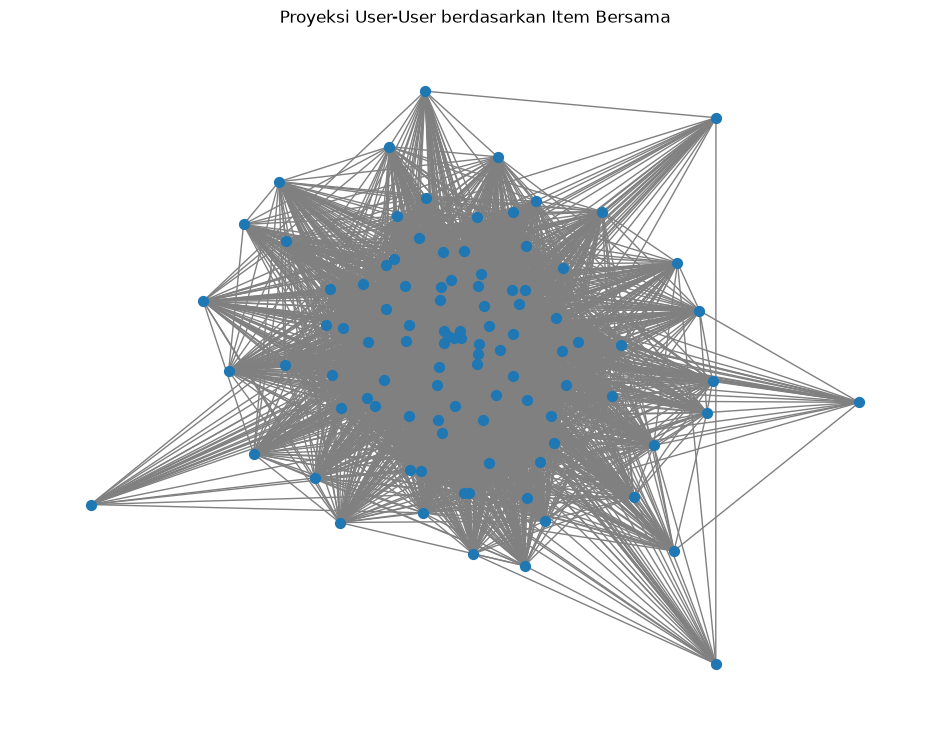

In [25]:
import networkx as nx
import matplotlib.pyplot as plt

jumlah_user_plot = min(100, vsm_user.shape[0])

aktivitas_user = vsm_user.getnnz(axis=1)
user_terpilih = aktivitas_user.argsort()[-jumlah_user_plot:][::-1]

vsm_plot = vsm_user[user_terpilih]

similarity_user = vsm_plot @ vsm_plot.T

G_user = nx.Graph()
G_user.add_nodes_from(range(jumlah_user_plot))

similarity_coo = similarity_user.tocoo()

for u, v, weight in zip(
    similarity_coo.row,
    similarity_coo.col,
    similarity_coo.data
):
    if u < v and weight > 0:
        G_user.add_edge(u, v, weight=int(weight))

print("Jumlah node graf:", G_user.number_of_nodes())
print("Jumlah edge graf:", G_user.number_of_edges())

plt.figure(figsize=(12, 9))
pos = nx.spring_layout(G_user, seed=42)

nx.draw_networkx(
    G_user,
    pos,
    with_labels=False,
    node_size=50,
    edge_color="gray"
)

plt.title("Proyeksi User-User berdasarkan Item Bersama")
plt.axis("off")
plt.show()

**Vector Space Modelling (VSM) terhadap Simpul User**

VSM User dibentuk dari data training (P1) dengan 1.201.045 baris interaksi, 606.763 Visitor unik, dan 162.894 Item unik. Matriks biner memiliki *shape* `(606763, 162894)`, dengan nilai 1 menunjukkan adanya interaksi dan 0 menunjukkan tidak adanya interaksi. Setelah duplikasi pasangan User–Item dihapus, tersisa 925.823 interaksi unik.

Karena matriks memiliki 98.838.052.122 posisi elemen dan sebagian besar bernilai nol, digunakan *sparse matrix* untuk menghemat memori. Visualisasi NetworkX pada 100 User dengan interaksi terbanyak menghasilkan 100 node dan 4.047 edge. Edge menunjukkan kesamaan Item yang pernah diinteraksikan oleh dua User. Hasil ini menggambarkan pola kemiripan antar-User dan dapat digunakan untuk analisis rekomendasi.

**NOMOR 5**

In [26]:
vsm_item = vsm_user.T.tocsr()

print("Dimensi VSM Item:", vsm_item.ndim)
print("Shape VSM Item:", vsm_item.shape)
print("Jumlah item:", vsm_item.shape[0])
print("Jumlah user:", vsm_item.shape[1])
print("Jumlah interaksi unik:", vsm_item.nnz)
print(
    "Jumlah elemen matriks:",
    vsm_item.shape[0] * vsm_item.shape[1]
)

Dimensi VSM Item: 2
Shape VSM Item: (162894, 606763)
Jumlah item: 162894
Jumlah user: 606763
Jumlah interaksi unik: 925823
Jumlah elemen matriks: 98838052122


Jumlah node graf: 100
Jumlah edge graf: 2209


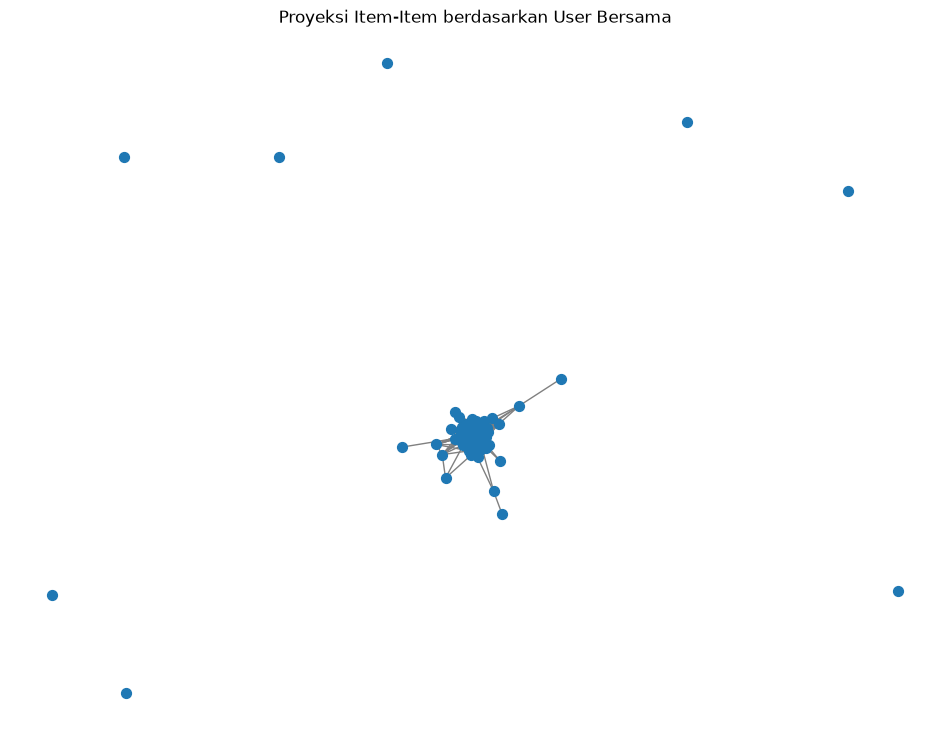

In [27]:
jumlah_item_plot = min(100, vsm_item.shape[0])

aktivitas_item = vsm_item.getnnz(axis=1)
item_terpilih = aktivitas_item.argsort()[-jumlah_item_plot:][::-1]

vsm_item_plot = vsm_item[item_terpilih]

similarity_item = vsm_item_plot @ vsm_item_plot.T

G_item = nx.Graph()
G_item.add_nodes_from(range(jumlah_item_plot))

similarity_coo = similarity_item.tocoo()

for u, v, weight in zip(
    similarity_coo.row,
    similarity_coo.col,
    similarity_coo.data
):
    if u < v and weight > 0:
        G_item.add_edge(u, v, weight=int(weight))

print("Jumlah node graf:", G_item.number_of_nodes())
print("Jumlah edge graf:", G_item.number_of_edges())

plt.figure(figsize=(12, 9))
pos = nx.spring_layout(G_item, seed=42)

nx.draw_networkx(
    G_item,
    pos,
    with_labels=False,
    node_size=50,
    edge_color="gray"
)

plt.title("Proyeksi Item-Item berdasarkan User Bersama")
plt.axis("off")
plt.show()

**Vector Space Modelling (VSM) terhadap Simpul Item**

VSM Item dibentuk dengan mentransposisi matriks VSM User, sehingga menghasilkan matriks Item–User dengan *shape* `(162894, 606763)`. Matriks memiliki 925.823 pasangan Item–User unik dan 98.838.052.122 posisi elemen. *Sparse matrix* digunakan untuk menghemat memori karena sebagian besar elemen bernilai nol.

Visualisasi NetworkX pada 100 Item dengan interaksi terbanyak menghasilkan 100 node dan 2.209 edge. Node merepresentasikan Item, sedangkan edge menunjukkan bahwa dua Item pernah diinteraksikan oleh User yang sama. Proyeksi ini membantu memahami keterkaitan antar-Item berdasarkan pola interaksi pengguna.

**NOMOR 6**
## Perbandingan Proyeksi User–User dan Item–Item

Berdasarkan hasil eksplorasi pada nomor 4 dan 5, diperoleh perbandingan sebagai berikut:

| Aspek | Proyeksi User–User | Proyeksi Item–Item |
|---|---:|---:|
| Jumlah simpul pada VSM | 606.763 User | 162.894 Item |
| Jumlah kolom VSM | 162.894 Item | 606.763 User |
| Interaksi unik | 925.823 | 925.823 |
| Node pada visualisasi | 100 | 100 |
| Edge pada visualisasi | 4.047 | 2.209 |

### Analisis Efektivitas dan Efisiensi

**Efektivitas:** Proyeksi User–User menghasilkan 4.047 edge pada visualisasi 100 User, sedangkan proyeksi Item–Item menghasilkan 2.209 edge pada visualisasi 100 Item. Hal ini menunjukkan bahwa hubungan antar-User pada kelompok yang divisualisasikan lebih padat. Proyeksi User–User sesuai untuk mengamati kesamaan pola interaksi antar-User.

**Efisiensi:** Proyeksi Item–Item memiliki jumlah simpul lebih sedikit, yaitu 162.894 Item dibandingkan 606.763 User. Jumlah simpul yang lebih sedikit berpotensi menguntungkan dari sisi ukuran graf. Namun, efisiensi komputasi secara keseluruhan juga dipengaruhi oleh jumlah edge, metode perhitungan kemiripan, dan kebutuhan memori.

### Kesimpulan

Apabila tujuan analisis adalah menemukan User dengan pola interaksi yang serupa, proyeksi User–User lebih relevan. Sementara itu, jika tujuan analisis adalah menemukan Item yang sering diinteraksikan oleh User yang sama, proyeksi Item–Item lebih sesuai.

Perbandingan ini masih bersifat eksploratif karena visualisasi hanya menggunakan 100 simpul terpilih. Oleh karena itu, kepadatan graf pada visualisasi belum cukup untuk menyimpulkan bahwa salah satu proyeksi lebih efisien secara keseluruhan.


**NOMOR 7**

a

In [28]:
import numpy as np

jumlah_interaksi_user = vsm_user.getnnz(axis=1)
ref_idx = int(np.argmax(jumlah_interaksi_user))
reference_user = int(visitor_ids[ref_idx])

dot_products = (
    vsm_user[ref_idx] @ vsm_user.T
).toarray().ravel()

norms = np.sqrt(
    vsm_user.multiply(vsm_user).sum(axis=1)
).A1

denominator = norms[ref_idx] * norms

similarities = np.divide(
    dot_products,
    denominator,
    out=np.zeros_like(dot_products, dtype=float),
    where=denominator != 0
)

similarities[ref_idx] = -1

top_indices = np.argsort(similarities)[-5:][::-1]

df_similarity = pd.DataFrame({
    "reference_user": reference_user,
    "similar_user": [
        int(visitor_ids[i]) for i in top_indices
    ],
    "similarity": similarities[top_indices]
})

print("User acuan:", reference_user)
display(df_similarity)

User acuan: 163561


,reference_user,similar_user,similarity
0,163561,286616,0.154959
1,163561,350566,0.145859
2,163561,57905,0.118498
3,163561,76757,0.114042
4,163561,138131,0.110602


b

In [29]:
records = [
    {
        "source": int(row.reference_user),
        "target": int(row.similar_user),
        "similarity": float(row.similarity)
    }
    for row in df_similarity.itertuples(index=False)
]

query_save = """
UNWIND $records AS row
MATCH (u:Visitor {visitorId: row.source})
MATCH (v:Visitor {visitorId: row.target})
MERGE (u)-[s:SIMILAR_TO]->(v)
SET s.similarity = row.similarity
RETURN count(s) AS jumlah_relasi
"""

query_read = """
MATCH (u:Visitor {visitorId: $reference_user})
      -[s:SIMILAR_TO]->(v:Visitor)
RETURN
    u.visitorId AS User_Acuan,
    v.visitorId AS User_Mirip,
    s.similarity AS Similarity
ORDER BY Similarity DESC
LIMIT 5
"""

with driver.session() as session:
    result = session.run(
        query_save,
        records=records
    )
    print(
        "Jumlah relasi disimpan:",
        result.single()["jumlah_relasi"]
    )
    result = session.run(
        query_read,
        reference_user=reference_user
    )
    df_hasil_neo4j = pd.DataFrame(
        [record.data() for record in result]
    )
print("\nLima User paling mirip dari Neo4j:")
display(df_hasil_neo4j)



Jumlah relasi disimpan: 5

Lima User paling mirip dari Neo4j:


,User_Acuan,User_Mirip,Similarity
0,163561,286616,0.154959
1,163561,350566,0.145859
2,163561,57905,0.118498
3,163561,76757,0.114042
4,163561,138131,0.110602


**NOMOR 8**

done


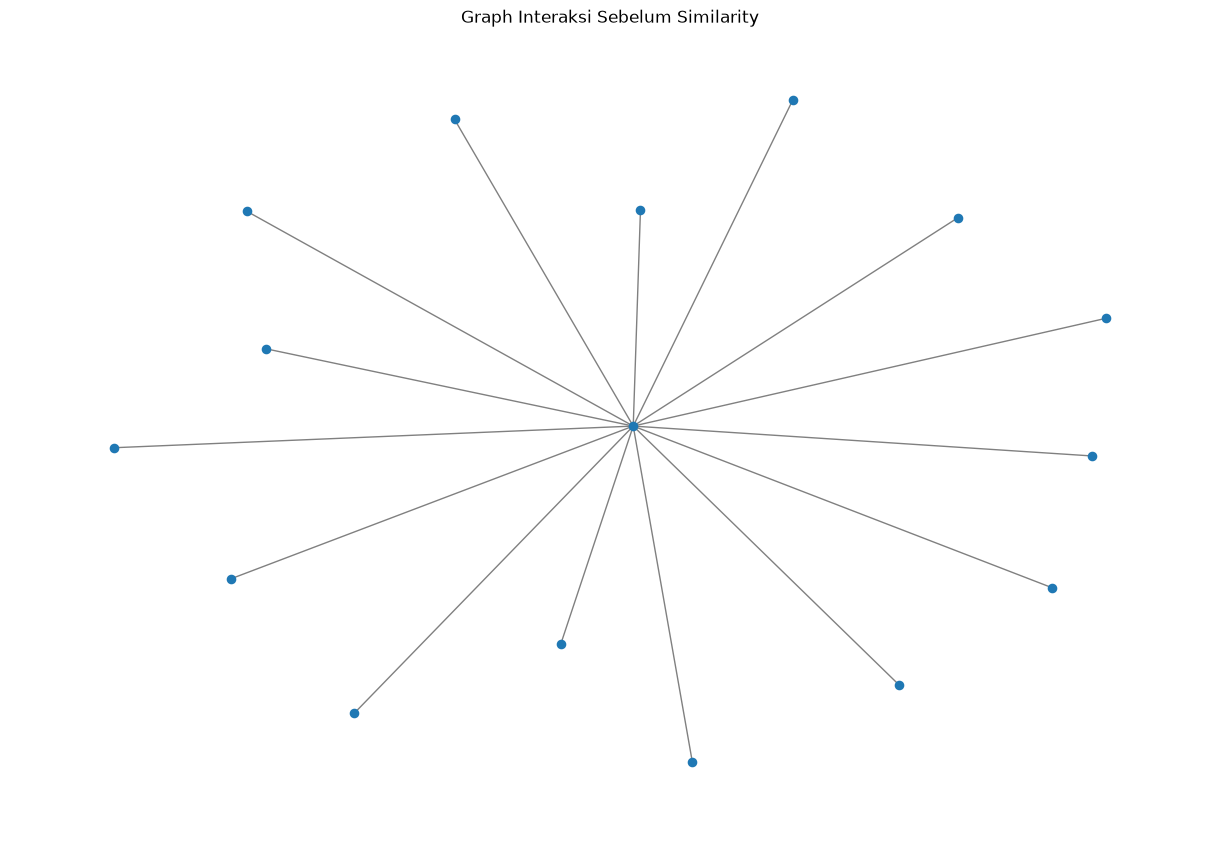

Jumlah simpul: 16
Jumlah relasi: 15


In [30]:

import matplotlib.pyplot as plt
import networkx as nx
from neo4j import GraphDatabase

query_sebelum = """
MATCH (v:Visitor)-[r]->(i:Item)
WHERE type(r) IN ['VIEWED', 'ADDED_TO_CART', 'BOUGHT']
RETURN v.visitorId AS visitor_id,
       i.itemId AS item_id,
       type(r) AS jenis_relasi
LIMIT 100
"""

try:
    with driver.session() as session:
        hasil = session.run(query_sebelum)
        data_sebelum = [record.data() for record in hasil]
finally:
    print("done")

G_sebelum = nx.Graph()

for row in data_sebelum:
    user = "User_" + str(row["visitor_id"])
    item = "Item_" + str(row["item_id"])

    G_sebelum.add_node(user, jenis="User")
    G_sebelum.add_node(item, jenis="Item")
    G_sebelum.add_edge(
        user, item,
        jenis_relasi=row["jenis_relasi"]
    )

plt.figure(figsize=(12, 8))
pos = nx.spring_layout(G_sebelum, seed=42)

nx.draw(
    G_sebelum, pos,
    with_labels=False,
    node_size=35,
    edge_color="gray"
)

plt.title("Graph Interaksi Sebelum Similarity")
plt.show()

print("Jumlah simpul:", G_sebelum.number_of_nodes())
print("Jumlah relasi:", G_sebelum.number_of_edges())


done


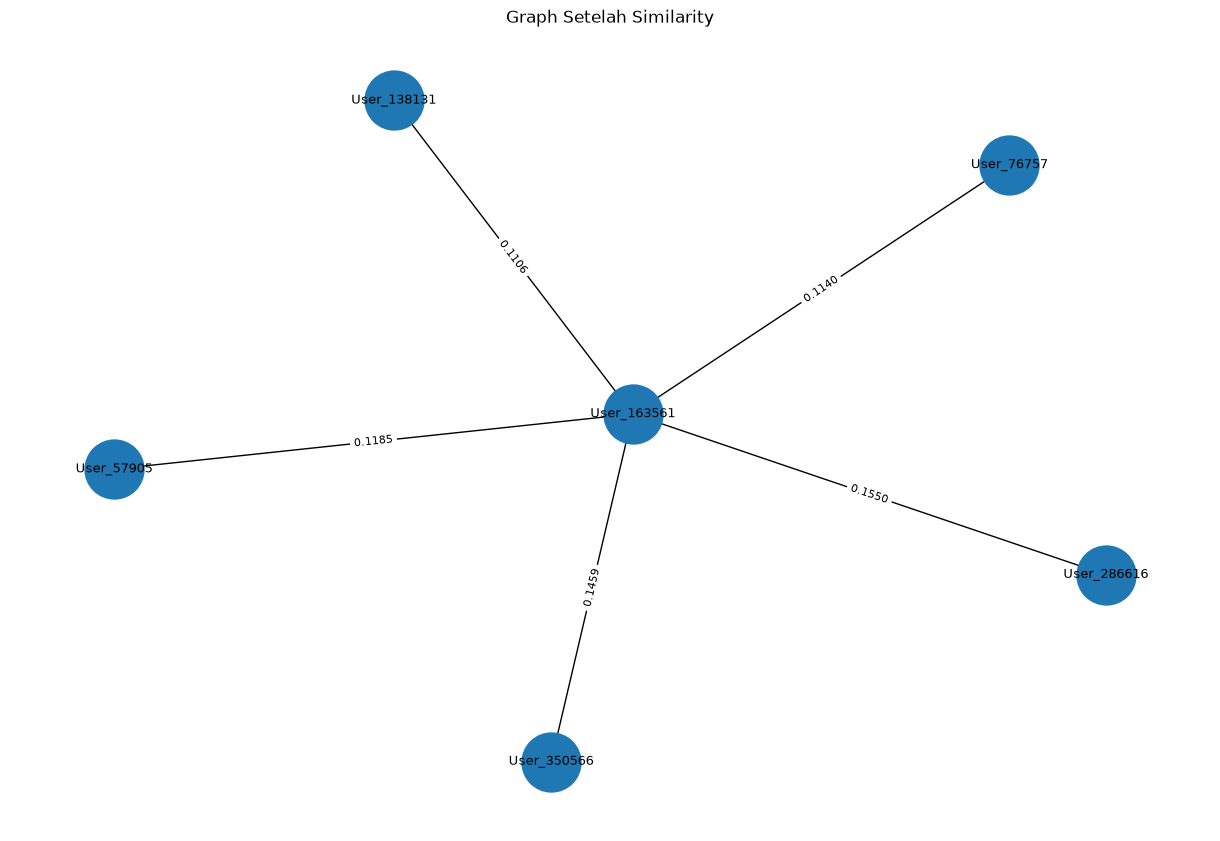

Jumlah simpul: 6
Jumlah relasi: 5


In [31]:

query_sesudah = """
MATCH (u:Visitor {visitorId: $reference_user})
      -[s:SIMILAR_TO]->(v:Visitor)
RETURN u.visitorId AS user_acuan,
       v.visitorId AS user_mirip,
       s.similarity AS similarity
ORDER BY similarity DESC
LIMIT 5
"""

try:
    with driver.session() as session:
        hasil = session.run(
            query_sesudah,
            reference_user=163561
        )
        data_sesudah = [record.data() for record in hasil]
finally:
    print("done")

G_sesudah = nx.Graph()

user_acuan = "User_163561"
G_sesudah.add_node(user_acuan, jenis="User Acuan")

for row in data_sesudah:
    user_mirip = "User_" + str(row["user_mirip"])

    G_sesudah.add_node(user_mirip, jenis="User Mirip")
    G_sesudah.add_edge(
        user_acuan,
        user_mirip,
        similarity=row["similarity"]
    )

pos = nx.spring_layout(G_sesudah, seed=42)

plt.figure(figsize=(12, 8))

nx.draw(
    G_sesudah, pos,
    with_labels=True,
    node_size=1800,
    font_size=9
)

edge_labels = {
    (u, v): f"{d['similarity']:.4f}"
    for u, v, d in G_sesudah.edges(data=True)
}

nx.draw_networkx_edge_labels(
    G_sesudah, pos,
    edge_labels=edge_labels,
    font_size=8
)

plt.title("Graph Setelah Similarity")
plt.show()

print("Jumlah simpul:", G_sesudah.number_of_nodes())
print("Jumlah relasi:", G_sesudah.number_of_edges())



### Analisis Hasil Visualisasi Graph

**Sebelum perhitungan similarity**, graph menunjukkan hubungan interaksi antara simpul User dan Item melalui relasi `VIEWED`, `ADDED_TO_CART`, dan `BOUGHT`. Visualisasi ini menggambarkan aktivitas pengguna terhadap item pada dataset RetailRocket.

**Sesudah perhitungan similarity**, graph menampilkan hubungan tambahan berupa relasi `SIMILAR_TO`. Relasi tersebut menghubungkan User acuan `163561` dengan lima User yang memiliki nilai similarity tertinggi berdasarkan perhitungan Cosine Similarity.

Penambahan relasi `SIMILAR_TO` memungkinkan graph merepresentasikan kemiripan pola interaksi antar-User, bukan hanya aktivitas interaksi antara User dan Item. Dengan demikian, hasil visualisasi memperlihatkan perubahan struktur informasi graph setelah proses perhitungan dan penyimpanan similarity.


### **2.2 Analytics**

**NOMOR 1**

A

In [32]:
from collections import Counter
from sklearn.neighbors import NearestNeighbors
from scipy.sparse import csr_matrix

SEED = 42
K = 5

print("Shape VSM:", vsm_user.shape)
print("Jumlah interaksi unik:", vsm_user.nnz)
print("Jumlah user:", len(visitor_ids))
print("Jumlah Item:", len(item_ids))

print(
    "Jumlah Item pada 10 user pertama:",
    vsm_user[:10].getnnz(axis=1)
)

Shape VSM: (606763, 162894)
Jumlah interaksi unik: 925823
Jumlah user: 606763
Jumlah Item: 162894
Jumlah Item pada 10 user pertama: [  2   4   4 929   2  24   2   5   3   4]


In [33]:
import numpy as np
from collections import Counter
from sklearn.neighbors import NearestNeighbors

SEED = 123
K = 5

jumlah_item_per_user = np.diff(vsm_user.indptr)
kandidat_user = np.where(jumlah_item_per_user >= 5)[0]

rng = np.random.default_rng(SEED)
urutan_target = rng.permutation(kandidat_user)

knn = NearestNeighbors(
    metric="cosine",
    algorithm="brute",
    n_jobs=-1
)
knn.fit(vsm_user)

target_idx = None

for idx in urutan_target:
    distances, indices = knn.kneighbors(
        vsm_user[idx],
        n_neighbors=K + 1
    )

    calon_neighbors = [
        (int(i), float(d))
        for i, d in zip(indices[0], distances[0])
        if int(i) != idx
    ][:K]

    items_target = set(vsm_user[idx].indices)
    calon_frekuensi = Counter()

    for neighbor_idx, distance in calon_neighbors:
        items_neighbor = set(vsm_user[neighbor_idx].indices)
        calon_frekuensi.update(items_neighbor - items_target)

    if len(calon_frekuensi) >= 3:
        target_idx = int(idx)
        neighbors = calon_neighbors
        frekuensi_item = calon_frekuensi
        break

if target_idx is not None:
    target_user = visitor_ids[target_idx]
    print("User target:", target_user)
    print("Jumlah kandidat item baru:", len(frekuensi_item))
else:
    print("Tidak ditemukan user dengan minimal 3 kandidat.")

User target: 1016574
Jumlah kandidat item baru: 4


In [34]:
from sklearn.neighbors import NearestNeighbors

K = 5

knn = NearestNeighbors(
    metric="cosine",
    algorithm="brute",
    n_jobs=-1
)

knn.fit(vsm_user)

distances, indices = knn.kneighbors(
    vsm_user[target_idx],
    n_neighbors=K + 1
)

neighbors = [
    (int(idx), float(distance))
    for idx, distance in zip(indices[0], distances[0])
    if int(idx) != target_idx
][:K]

print("5 tetangga terdekat untuk user:", target_user)

for i, (neighbor_idx, distance) in enumerate(neighbors, start=1):
    print(
        f"{i}. User ID: {visitor_ids[neighbor_idx]} | "
        f"Similarity: {1 - distance:.4f}"
    )

5 tetangga terdekat untuk user: 1016574
1. User ID: 903380 | Similarity: 0.6325
2. User ID: 1013679 | Similarity: 0.5477
3. User ID: 972768 | Similarity: 0.5164
4. User ID: 603358 | Similarity: 0.4472
5. User ID: 198651 | Similarity: 0.4472


B

In [35]:
from collections import Counter

items_target = set(vsm_user[target_idx].indices)
frekuensi_item = Counter()

for neighbor_idx, distance in neighbors:
    items_neighbor = set(vsm_user[neighbor_idx].indices)
    items_baru = items_neighbor - items_target
    frekuensi_item.update(items_baru)

print("User target:", target_user)
print("Jumlah item milik target:", len(items_target))
print("Jumlah kandidat item baru:", len(frekuensi_item))

User target: 1016574
Jumlah item milik target: 5
Jumlah kandidat item baru: 4


In [36]:
rekomendasi = sorted(
    frekuensi_item.items(),
    key=lambda x: (-x[1], item_ids[x[0]])
)[:3]

if rekomendasi:
    print("3 rekomendasi item untuk user:", target_user)

    for peringkat, (item_idx, frekuensi) in enumerate(
        rekomendasi, start=1
    ):
        print(
            f"{peringkat}. Item ID: {item_ids[item_idx]} | "
            f"Jumlah tetangga yang berinteraksi: {frekuensi}"
        )
else:
    print("Belum ada kandidat item baru dari 5 tetangga.")

3 rekomendasi item untuk user: 1016574
1. Item ID: 31406 | Jumlah tetangga yang berinteraksi: 1
2. Item ID: 63846 | Jumlah tetangga yang berinteraksi: 1
3. Item ID: 277105 | Jumlah tetangga yang berinteraksi: 1


### **2**

In [37]:
import numpy as np

target_user_1b = 1016574
recommended_items_1b = [31406, 63846, 277105]

actual_items_1b = set(
    p2.loc[
        p2["visitorid"] == target_user_1b,
        "itemid"
    ].unique()
)

relevance = [
    int(item in actual_items_1b)
    for item in recommended_items_1b
]

# Hit@5
hit_at_5 = int(sum(relevance) > 0)

# DCG@5
dcg_at_5 = sum(
    rel / np.log2(rank + 1)
    for rank, rel in enumerate(relevance, start=1)
)

# IDCG@5
ideal_rel_count = min(len(actual_items_1b), 5)

idcg_at_5 = sum(
    1 / np.log2(rank + 1)
    for rank in range(1, ideal_rel_count + 1)
)

# NDCG@5
ndcg_at_5 = (
    dcg_at_5 / idcg_at_5
    if idcg_at_5 > 0 else 0.0
)

print("User target:", target_user_1b)
print("Item aktual P2:", actual_items_1b)
print("Item rekomendasi:", recommended_items_1b)
print("Relevansi:", relevance)
print(f"Hit@5: {hit_at_5}")
print(f"NDCG@5: {ndcg_at_5:.4f}")

User target: 1016574
Item aktual P2: set()
Item rekomendasi: [31406, 63846, 277105]
Relevansi: [0, 0, 0]
Hit@5: 0
NDCG@5: 0.0000
